In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv('units_L234.csv').copy()

In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [4]:
units_cleaned = clean_dataset(units)

In [5]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [6]:
E_L23 = units_cleaned[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [11]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [12]:


def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1(pre_pop, post_pop, synapses, metric)
    print(len(conn_dist))
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    print(len(pot_dist))

    """conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()"""

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )
    global id_map, all_ids
    all_ids = pd.Index(pd.concat([
    df['pre_pt_root_id'],
    df['post_pt_root_id']
    ]).unique())
    id_map = {id_: i for i, id_ in enumerate(all_ids)}

    # active_ids = pd.Index(pd.concat([
    #     conn_dist['pre_pt_root_id'],
    #     conn_dist['post_pt_root_id']
    # ]).unique())

    # active_ids_index = active_ids.map(id_map).values



    pre_idx = df['pre_pt_root_id'].map(id_map).values
    post_idx = df['post_pt_root_id'].map(id_map).values


    
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    X = df[features].values
    y = df['label'].values

    return X, y, features, pre_idx, post_idx

In [13]:
path, pre, post = pathways[0]
X, y, features, pre_idx, post_idx = build_dataset(pre, post, synapses, metric=['Euclidean'])

40020
5525520
metri vaut ['Euclidean']


In [14]:
import os
import json
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import roc_auc_score

# =========================
# Config
# =========================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

CHECKPOINT_DIR = "checkpoints_embedding_MLP_distance_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BATCH_SIZE = 32768
N_EPOCHS = 30
PATIENCE = 5
LR = 1e-2
DIMS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)




Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [15]:
# =========================
# Model
# =========================


class EmbeddingModel(nn.Module):
    def __init__(self, n_neurons, dim=20, hidden=32):
        super().__init__()

        self.dim = dim
        self.Z = nn.Embedding(n_neurons, dim)
        nn.init.normal_(self.Z.weight, mean=0.0, std=0.1)

        self.mlp = nn.Sequential(
            nn.Linear(1, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward_logits(self, pre_idx, post_idx):
        zi = self.Z(pre_idx)
        zj = self.Z(post_idx)

        dist2 = ((zi - zj) ** 2).mean(dim=1, keepdim=True)

        logits = self.mlp(dist2).squeeze(1)
        return logits

    def forward(self, pre_idx, post_idx):
        return torch.sigmoid(self.forward_logits(pre_idx, post_idx))

In [16]:
# =========================
# Data
# =========================

_, y, _, pre_idx, post_idx = build_dataset(
    pre, post, synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

40020
5525520
metri vaut ['Euclidean']
n_neurons: 13157
n_pairs: 5525520
positive rate: 0.007242757361382246


In [17]:
# =========================
# Eval
# =========================

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_y = []
    all_preds = []

    with torch.no_grad():
        for pi, pj, yb in loader:

            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(yb)
            all_y.append(yb.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_y = np.concatenate(all_y)
    all_preds = np.concatenate(all_preds)

    auc = roc_auc_score(all_y, all_preds)

    return total_loss / len(loader.dataset), auc


In [18]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [19]:
import os

dim = 1  # change selon la dimension qui plante
bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)

In [42]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [43]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = EmbeddingModel(n_neurons=n_neurons, dim=dim).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            logits = model.forward_logits(pi, pj)
            loss = criterion(logits, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
dim=01 | epoch=000 | train_loss=1.2391 | val_loss=1.1086 | val_auc=0.7853
dim=01 | epoch=001 | train_loss=0.9664 | val_loss=1.1655 | val_auc=0.7953
dim=01 | epoch=002 | train_loss=0.9102 | val_loss=1.3502 | val_auc=0.7985
dim=01 | epoch=003 | train_loss=0.9002 | val_loss=1.3930 | val_auc=0.7988
dim=01 | epoch=004 | train_loss=0.8949 | val_loss=1.5629 | val_auc=0.7993
dim=01 | epoch=005 | train_loss=0.8910 | val_loss=1.6608 | val_auc=0.7993
dim=01 | epoch=006 | train_loss=0.8866 | val_loss=1.8217 | val_auc=0.7992
dim=01 | epoch=007 | train_loss=0.8806 | val_loss=1.9990 | val_auc=0.7983
dim=01 | epoch=008 | train_loss=0.8713 | val_loss=1.8744 | val_auc=0.7958
dim=01 | epoch=009 | train_loss=0.8603 | val_loss=1.7488 | val_auc=0.7977
Early stopping at epoch 9 | best_epoch=4 | best_val_auc=0.7993
BEST dim=01 | epoch=4 | val_auc=0.7993 | test_auc=0.8006

Training dim = 2
dim=02 | epoch=000 | train_loss=1.2215 | val_loss=1.0958 | val_auc=0.7927
dim=02 | epoch=001 | train_los

In [21]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1

ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = EmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

df_Z_full = df_Z.merge(
    units_cleaned,
    on="pt_root_id",
    how="left"
)

print(df_Z_full.head())
print(df_Z_full.shape)



Loaded model for dim=1
Best epoch: 4
Best val loss: 1.5629
Z shape: (13157, 1)
         z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0 -0.170814           0  864691134919349258     655.761963     197.912964   
1 -0.057744           1  864691134941217635     723.241577     113.938652   
2  0.109330           2  864691134941412707     703.805298     173.077713   
3  0.029924           3  864691134941495395     672.241821     235.717133   
4 -0.184170           4  864691134949221372     594.002869     210.626678   

   pt_position_z classification_system            strategy_axon layer  \
0     819.440002     excitatory_neuron  axon_partially_extended  L2/3   
1     863.000000     excitatory_neuron      axon_fully_extended  L2/3   
2     872.119995     excitatory_neuron  axon_partially_extended  L2/3   
3     871.119995     excitatory_neuron  axon_partially_extended  L2/3   
4     787.919983     excitatory_neuron  axon_partially_extended  L2/3   

   gOSI_data select

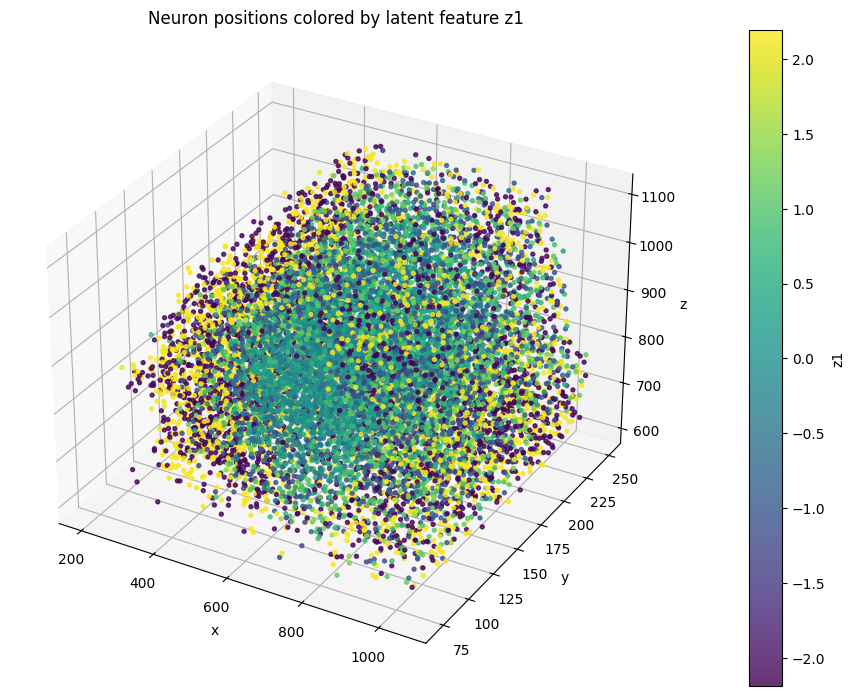

In [22]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_33816\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


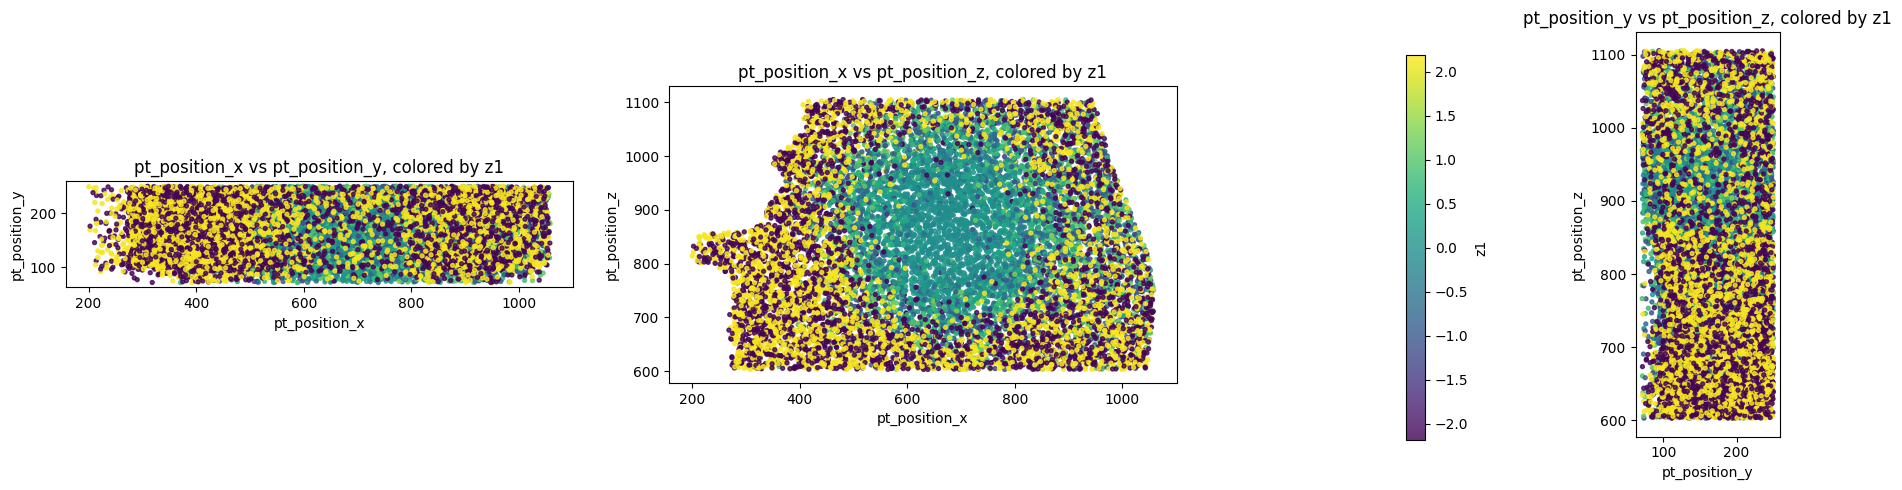

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [24]:
for coord in ["pt_position_x", "pt_position_y", "pt_position_z"]:
    corr = df_plot["z1"].corr(df_plot[coord])
    print(f"corr(z1, {coord}) = {corr:.3f}")

corr(z1, pt_position_x) = -0.005
corr(z1, pt_position_y) = -0.001
corr(z1, pt_position_z) = -0.007


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_33816\776809946.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = df.groupby("distance_bin").agg(


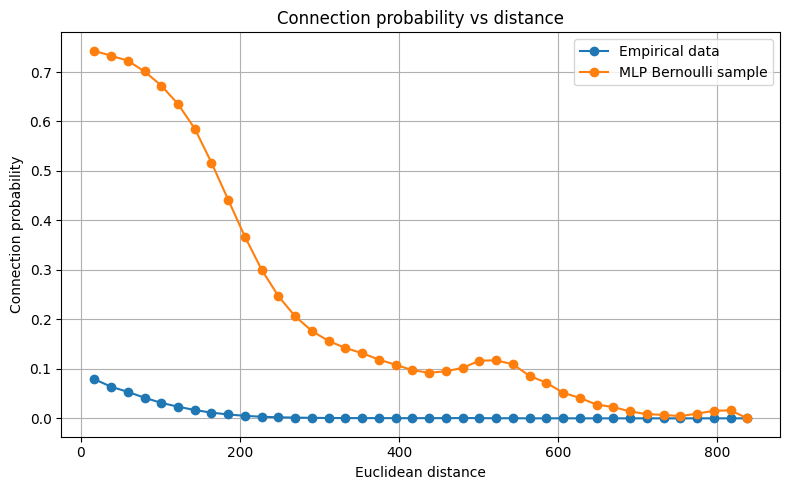

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================
# 1. Pair ids
# =========================

idx_to_id = np.array(all_ids)

pre_ids = idx_to_id[pre_idx.cpu().numpy()]
post_ids = idx_to_id[post_idx.cpu().numpy()]

# =========================
# 2. Euclidean distances
# =========================

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(pre_pos - post_pos, axis=1)

# =========================
# 3. MLP probabilities
# =========================

model.eval()

with torch.no_grad():
    p_mlp = model(
        pre_idx.to(DEVICE),
        post_idx.to(DEVICE)
    ).cpu().numpy()

# =========================
# 4. Bernoulli realization
# =========================

rng = np.random.default_rng(42)

y_mlp = rng.binomial(
    n=1,
    p=p_mlp
)

y_emp = y.cpu().numpy()

# =========================
# 5. Build dataframe
# =========================

df = pd.DataFrame({
    "distance": distance,
    "empirical": y_emp,
    "mlp": y_mlp
})

df["distance_bin"] = pd.cut(
    df["distance"],
    bins=40
)

# =========================
# 6. Compute connection probability per bin
# =========================

curve = df.groupby("distance_bin").agg(
    empirical_prob=("empirical", "mean"),
    mlp_prob=("mlp", "mean"),
    n_pairs=("empirical", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# =========================
# 7. Plot
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    centers,
    curve["empirical_prob"],
    marker="o",
    label="Empirical data"
)

plt.plot(
    centers,
    curve["mlp_prob"],
    marker="o",
    label="MLP Bernoulli sample"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()